# Projeto Final – Análise de Dados em FAE
**Aluno:** João | **Canal:** e⁺e⁻ | **Região:** Δm_ll < 25 GeV | **Sinal:** tt̄ | **Fundo:** DY e VV | **Dados:** Data_DoubleEG (G + H)

Import packages and define cosmetic functions<br>
=================================================================================================

In [22]:
import os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gs
import uproot

def style(ax, legend=True):
    ax.grid(which='major', axis='x', linewidth=0.2, linestyle='-', color='0.75')
    ax.grid(which='major', axis='y', linewidth=0.2, linestyle='-', color='0.75')
    ax.tick_params(which='major', length=8)
    ax.tick_params(which='minor', length=4)
    for s in ax.spines.values():
        s.set_linewidth(1)
    ax.margins(x=0)
    if legend:
        ax.legend(numpoints=1, ncol=1, prop={'size': 10.5}, frameon=False, loc='upper right')

def labels(ax, xlabel=None, ylabel=None):
    if xlabel is not None:
        ax.set_xlabel(xlabel, size=14, horizontalalignment='right', x=1.0)
    if ylabel is not None:
        ax.set_ylabel(ylabel, size=14, horizontalalignment='right', y=1.0)

Read files and save information in dataframes<br>
=================================================================================================

In [23]:
Data_DoubleEG_G_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/Data_DoubleEG_G_1_16_files_0_46/Tree.root")
Data_DoubleEG_H_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/Data_DoubleEG_H_1_16_files_0_85/Tree.root")
DYJetsToLL_PtZ_3To50_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-3To50_1_16_files_0_124/Tree.root")
DYJetsToLL_PtZ_50To100_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-50To100_1_16_files_0_89/Tree.root")
DYJetsToLL_PtZ_100To250_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-100To250_1_16_files_0_75/Tree.root")
DYJetsToLL_PtZ_250To400_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-250To400_1_16_files_0_46/Tree.root")
DYJetsToLL_PtZ_400To650_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-400To650_1_16_files_0_17/Tree.root")
DYJetsToLL_PtZ_650ToInf_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/DYJetsToLL_PtZ-650ToInf_1_16_files_0_16/Tree.root")
TTTo2L2Nu_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/TTTo2L2Nu_1_16_files_0_48/Tree.root") ##signal
WWTo2L2Nu_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/WWTo2L2Nu_1_16_files_0_6/Tree.root")
ZZTo2L2Nu_file = uproot.open("/home/jlima/introducao_analise_de_dados_UERJ/projeto_final/ZZTo2L2Nu_1_16_files_0_14/Tree.root")

ds = {}
ds["Data_DoubleEG_G"] = Data_DoubleEG_G_file["selection"].arrays(library="pd")
ds["Data_DoubleEG_H"] = Data_DoubleEG_H_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_3To50"] = DYJetsToLL_PtZ_3To50_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_50To100"] = DYJetsToLL_PtZ_50To100_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_100To250"] = DYJetsToLL_PtZ_100To250_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_250To400"] = DYJetsToLL_PtZ_250To400_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_400To650"] = DYJetsToLL_PtZ_400To650_file["selection"].arrays(library="pd")
ds["DYJetsToLL_PtZ_650ToInf"] = DYJetsToLL_PtZ_650ToInf_file["selection"].arrays(library="pd")
ds["TTTo2L2Nu"] = TTTo2L2Nu_file["selection"].arrays(library="pd")
ds["WWTo2L2Nu"] = WWTo2L2Nu_file["selection"].arrays(library="pd")
ds["ZZTo2L2Nu"] = ZZTo2L2Nu_file["selection"].arrays(library="pd")

print(list(ds["TTTo2L2Nu"].columns))   # confere os nomes das variáveis
print("\nColunas:", list(ds["TTTo2L2Nu"].columns))

['evtWeight', 'RecoLepID', 'LepLep_deltaM', 'LepLep_mass', 'LepLep_deltaR', 'LepLep_pt', 'LeadingLep_pt', 'TrailingLep_pt', 'MET_LepLep_deltaPhi', 'MET_LepLep_Mt', 'MET_pt', 'HLT_DoubleEle', 'HLT_DoubleMu', 'HLT_EleMu', 'genWeight', 'Nbjets', 'Njets', 'HT', 'BJetLep_mass', 'BJetLep_deltaR']

Colunas: ['evtWeight', 'RecoLepID', 'LepLep_deltaM', 'LepLep_mass', 'LepLep_deltaR', 'LepLep_pt', 'LeadingLep_pt', 'TrailingLep_pt', 'MET_LepLep_deltaPhi', 'MET_LepLep_Mt', 'MET_pt', 'HLT_DoubleEle', 'HLT_DoubleMu', 'HLT_EleMu', 'genWeight', 'Nbjets', 'Njets', 'HT', 'BJetLep_mass', 'BJetLep_deltaR']


Metadata, luminosity weight and grouping of processes<br>
=================================================================================================
Peso do evento: genWeight x σ·L / sigma genWeight (soma de pesos da tabela do projeto). Dados têm peso 1.

In [24]:
Data_luminosity = 16393.3805 #pb^-1

md = {} #                       [Cross section [pb], Generator weights sum]
md["DYJetsToLL_PtZ_3To50"] =    [1414,      123866571129.0938]
md["DYJetsToLL_PtZ_50To100"] =  [378.97,    46921372350.48828]
md["DYJetsToLL_PtZ_100To250"] = [93.1366,   6025316696.791992]
md["DYJetsToLL_PtZ_250To400"] = [3.7093,    152821361.0812912]
md["DYJetsToLL_PtZ_400To650"] = [0.515,     3369752.256501198]
md["DYJetsToLL_PtZ_650ToInf"] = [0.048934,  332449.5045676231]
md["TTTo2L2Nu"] =               [88.51,     721135180.715332]
md["WWTo2L2Nu"] =               [11.09,     32147079.16720963]
md["ZZTo2L2Nu"] =               [1.07118,   9737381.869026184]

for process in ds.keys():
    if process[:4] != "Data":
        ds[process]["evtWeight"] = ds[process]["genWeight"]*(md[process][0]*Data_luminosity/md[process][1])
    else:
        ds[process]["evtWeight"] = 1.0   # dados: peso 1

ds["Data"] = pd.concat([ds["Data_DoubleEG_G"], ds["Data_DoubleEG_H"]]).reset_index(drop=True)
del ds["Data_DoubleEG_G"], ds["Data_DoubleEG_H"]
ds["DYJetsToLL"] = pd.concat([ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]]).reset_index(drop=True)
del ds["DYJetsToLL_PtZ_3To50"], ds["DYJetsToLL_PtZ_50To100"], ds["DYJetsToLL_PtZ_100To250"], ds["DYJetsToLL_PtZ_250To400"], ds["DYJetsToLL_PtZ_400To650"], ds["DYJetsToLL_PtZ_650ToInf"]
ds["TT"] = ds["TTTo2L2Nu"].reset_index(drop=True)
del ds["TTTo2L2Nu"]
ds["VV"] = pd.concat([ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]]).reset_index(drop=True)
del ds["WWTo2L2Nu"], ds["ZZTo2L2Nu"]

Selections and cutflow<br>
=================================================================================================
- Canal ee: `RecoLepID == 11` e `HLT_DoubleEle`
- Região da proposta: `|LepLep_deltaM| < 25`
- Plateau do trigger: `LeadingLep_pt > 40` e `TrailingLep_pt > 20`
- Enriquecimento de ttbar (signal): `Nbjets >= 1` e `Njets >= 2`

In [25]:
DELTAM_MAX = 25.   # GeV
LEAD_MIN   = 40.   # GeV
TRAIL_MIN  = 20.   # GeV
NB_MIN     = 1
NJ_MIN     = 2

# 1) canal ee + trigger
df_channel = ds.copy()
for process in df_channel.keys():
    df_channel[process] = df_channel[process][(df_channel[process]["RecoLepID"] == 11) & (df_channel[process]["HLT_DoubleEle"])]

# 2) janela do Z ((absDelta m_ll) < 25 GeV)
df_zwindow = df_channel.copy()
for process in df_zwindow.keys():
    df_zwindow[process] = df_zwindow[process][df_zwindow[process]["LepLep_deltaM"].abs() < DELTAM_MAX]

# 3) plateau do trigger  ->  essa a regiao
df_region = df_zwindow.copy()
for process in df_region.keys():
    df_region[process] = df_region[process][(df_region[process]["LeadingLep_pt"] > LEAD_MIN) & (df_region[process]["TrailingLep_pt"] > TRAIL_MIN)]

# 4) selecao de sinal (enriquecimento de ttbar)
df_signal = df_region.copy()
for process in df_signal.keys():
    df_signal[process] = df_signal[process][(df_signal[process]["Nbjets"] >= NB_MIN) & (df_signal[process]["Njets"] >= NJ_MIN)]

# Cutflow: eventos esperados (MC) e eventos observados (dados)
print(f"{'corte':34s} {'DY':>9s} {'VV':>9s} {'TT':>9s} {'MC total':>10s} {'Dados':>8s} {'Dados/MC':>9s} {'TT/MC':>7s}")
for name, d in [("Selecao base (ja nas amostras)", ds),
                ("+ RecoLepID==11 & HLT_DoubleEle", df_channel),
                ("+ |deltaM| < 25 GeV", df_zwindow),
                ("+ plateau (lead>40, trail>20)", df_region),
                ("+ Nbjets>=1 & Njets>=2", df_signal)]:
    DY = d["DYJetsToLL"]["evtWeight"].sum()
    VV = d["VV"]["evtWeight"].sum()
    TT = d["TT"]["evtWeight"].sum()
    MC = DY + VV + TT
    print(f"{name:34s} {DY:9.1f} {VV:9.1f} {TT:9.1f} {MC:10.1f} {len(d['Data']):8d} {len(d['Data'])/MC:9.3f} {TT/MC:7.3f}")

corte                                     DY        VV        TT   MC total    Dados  Dados/MC   TT/MC
Selecao base (ja nas amostras)       46855.5    4086.7  125857.9   176800.1    63758     0.361   0.712
+ RecoLepID==11 & HLT_DoubleEle      17088.7     868.8   24982.1    42939.6    50076     1.166   0.582
+ |deltaM| < 25 GeV                  15488.3     365.4    8120.3    23973.9    30016     1.252   0.339
+ plateau (lead>40, trail>20)        15031.0     353.5    7655.7    23040.2    29109     1.263   0.332
+ Nbjets>=1 & Njets>=2                 786.4       7.8    4758.9     5553.1     5333     0.960   0.857


Basic variables: signal vs background (shapes) <br>
=================================================================================================
Só a seleção do canal (ee + trigger). Serve para ver quais variáveis separam tt̄ de DY e VV.

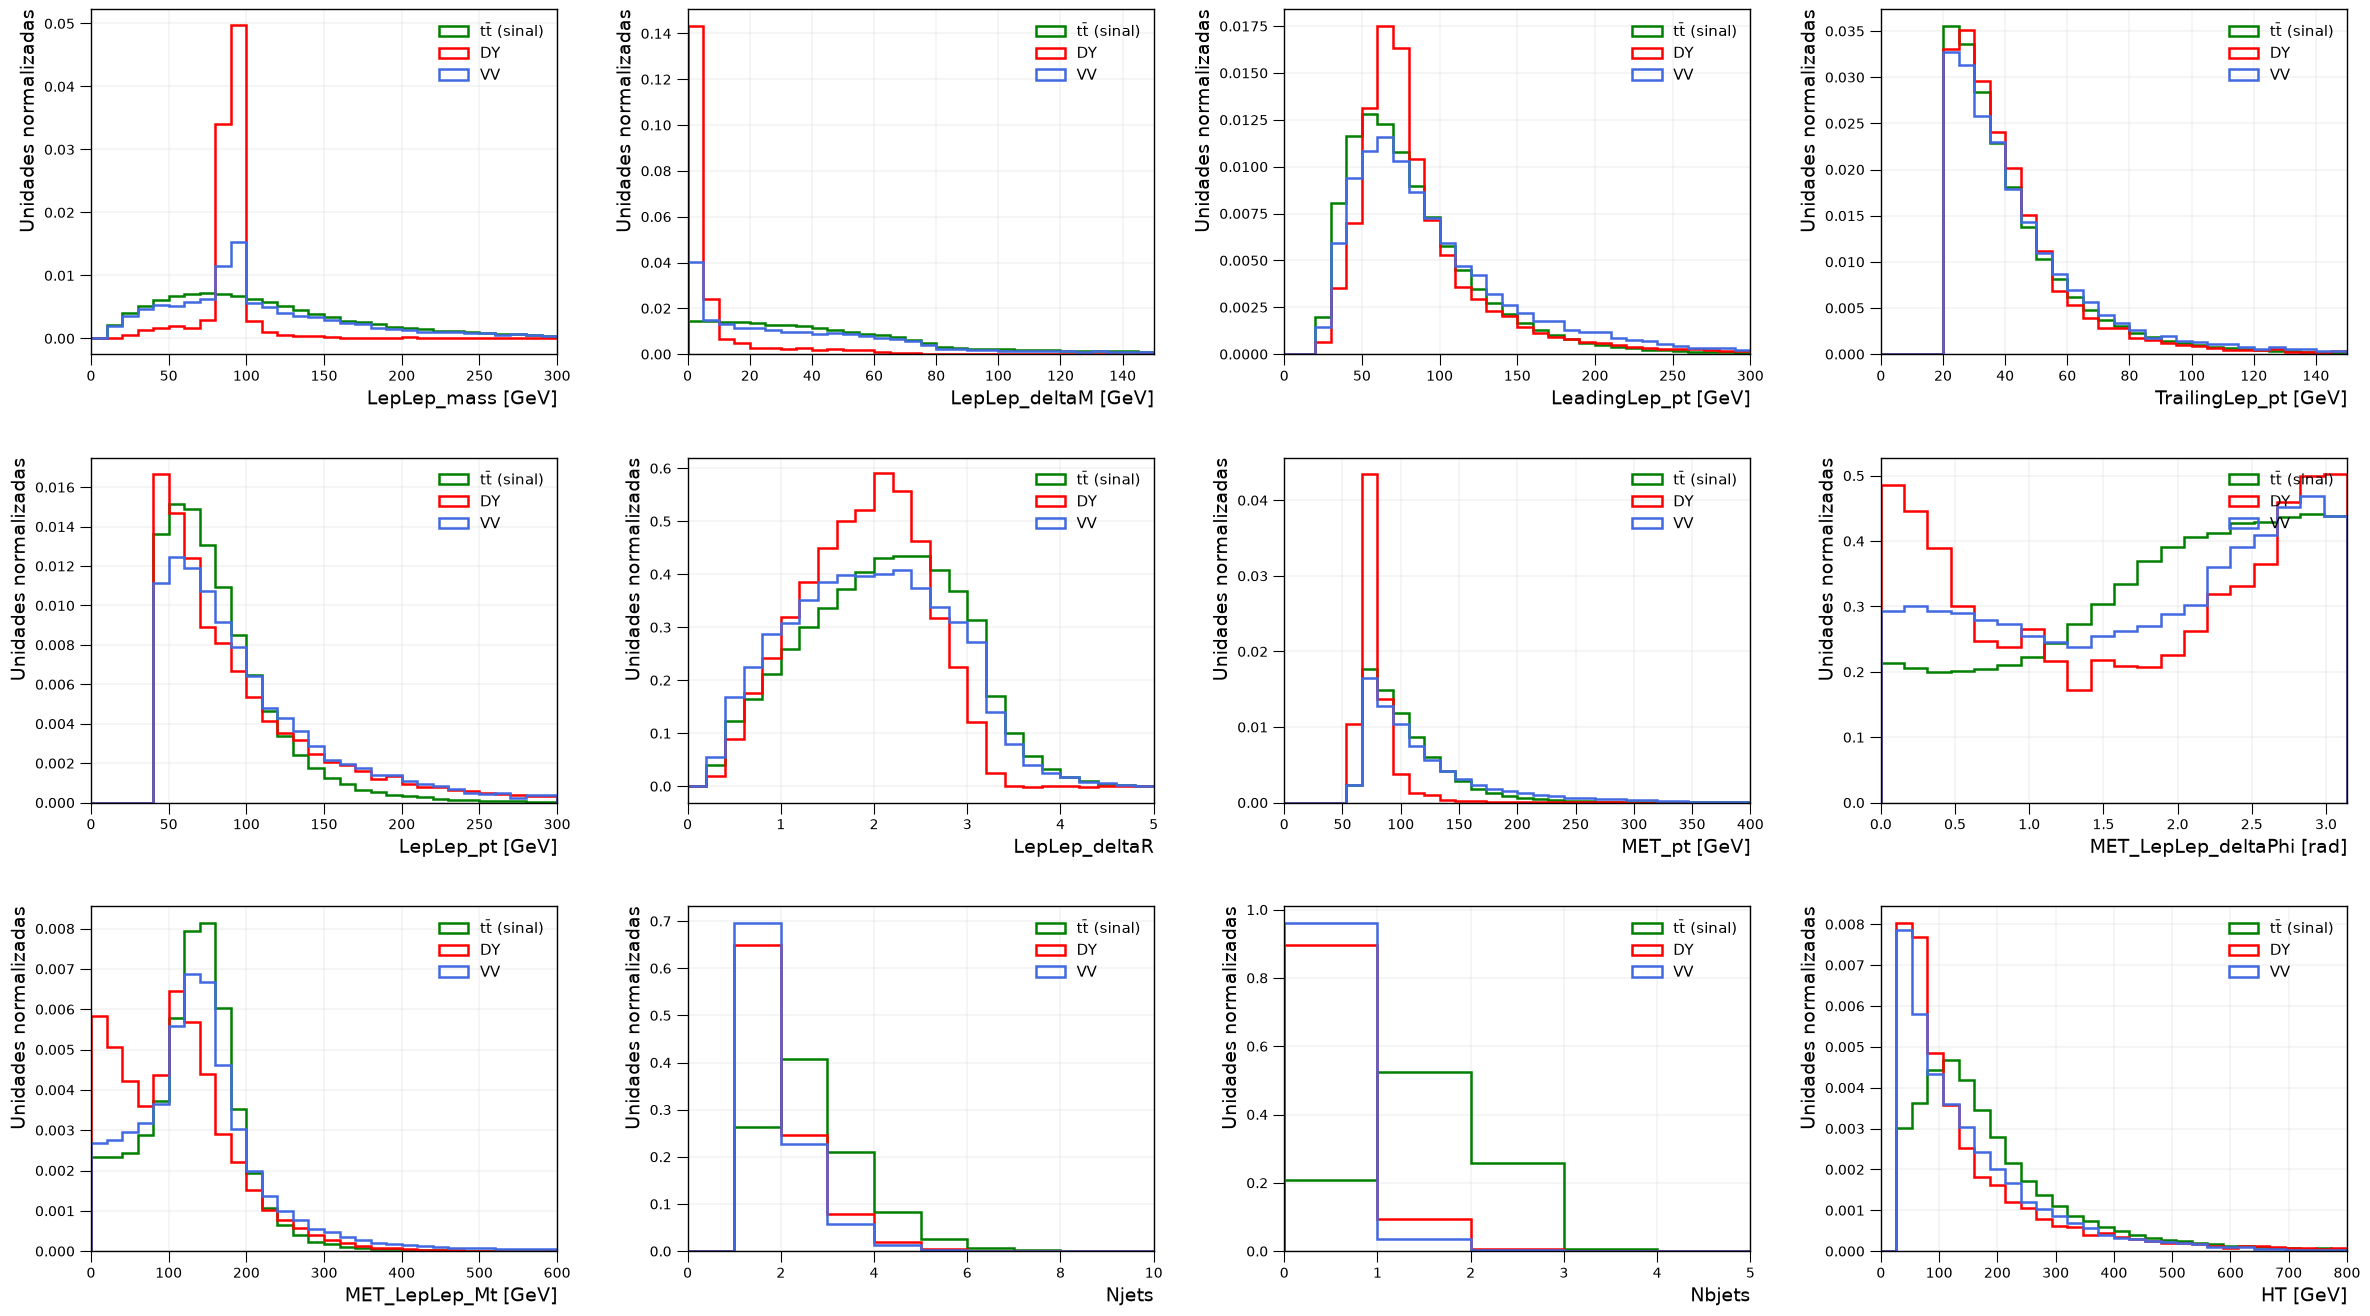

In [26]:
df = df_channel

fig1 = plt.figure(figsize=(24,13.5))
grid = [3, 4]
gs1 = gs.GridSpec(grid[0], grid[1])
#
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0])
var = "LepLep_mass"
bins = np.linspace(0., 300, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1])
var = "LepLep_deltaM"
bins = np.linspace(0., 150, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="LepLep_deltaM [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[2])
var = "LeadingLep_pt"
bins = np.linspace(0., 300, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3])
var = "TrailingLep_pt"
bins = np.linspace(0., 150, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4])
var = "LepLep_pt"
bins = np.linspace(0., 300, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="LepLep_pt [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[5])
var = "LepLep_deltaR"
bins = np.linspace(0., 5, 26)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="LepLep_deltaR", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6])
var = "MET_pt"
bins = np.linspace(0., 400, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="MET_pt [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7])
var = "MET_LepLep_deltaPhi"
bins = np.linspace(0., np.pi, 21)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="MET_LepLep_deltaPhi [rad]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[8])
var = "MET_LepLep_Mt"
bins = np.linspace(0., 600, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="MET_LepLep_Mt [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9])
var = "Njets"
bins = np.linspace(0., 10, 11)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="Njets", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10])
var = "Nbjets"
bins = np.linspace(0., 5, 6)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="Nbjets", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[11])
var = "HT"
bins = np.linspace(0., 800, 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8, color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True, linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8, color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="HT [GeV]", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
plt.subplots_adjust(left=0.05, bottom=0.06, right=0.99, top=0.98, wspace=0.28, hspace=0.3)
plt.savefig('shapes_antes_da_regiao.pdf')
plt.savefig('shapes_antes_da_regiao.png', dpi=400)

Check trigger efficiency plots<br>
=================================================================================================
Canal ee, trigger `HLT_DoubleEle`. Eventos com `RecoLepID == 11`, ainda sem exigir o trigger. Eficiência = (com trigger) / (todos).

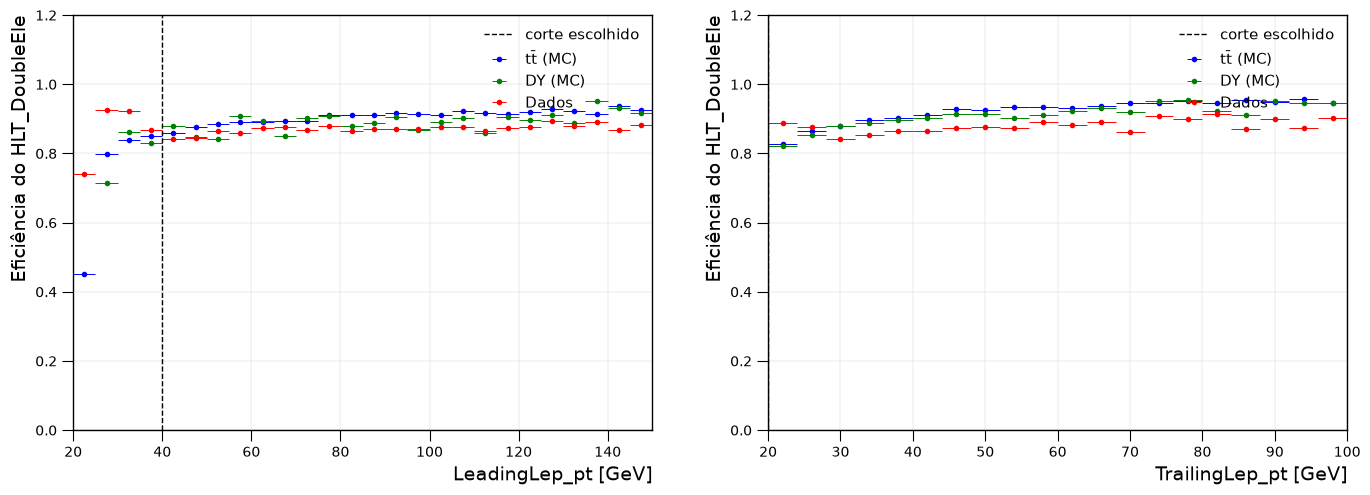

In [27]:
dfee = ds.copy()
for process in dfee.keys():
    dfee[process] = dfee[process][dfee[process]["RecoLepID"] == 11]

fig1 = plt.figure(figsize=(14,5))
grid = [1, 2]
gs1 = gs.GridSpec(grid[0], grid[1])
#
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0])
var = "LeadingLep_pt"
bins = np.linspace(0., 150, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
TT_den = np.histogram(dfee["TT"][var], bins=bins, weights=dfee["TT"]["evtWeight"])[0]
TT_num = np.histogram(dfee["TT"][dfee["TT"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["TT"][dfee["TT"]["HLT_DoubleEle"]]["evtWeight"])[0]
DY_den = np.histogram(dfee["DYJetsToLL"][var], bins=bins, weights=dfee["DYJetsToLL"]["evtWeight"])[0]
DY_num = np.histogram(dfee["DYJetsToLL"][dfee["DYJetsToLL"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["DYJetsToLL"][dfee["DYJetsToLL"]["HLT_DoubleEle"]]["evtWeight"])[0]
Data_den = np.histogram(dfee["Data"][var], bins=bins, weights=dfee["Data"]["evtWeight"])[0]
Data_num = np.histogram(dfee["Data"][dfee["Data"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["Data"][dfee["Data"]["HLT_DoubleEle"]]["evtWeight"])[0]
TT_efficiency = np.divide(TT_num, TT_den, out=np.full_like(TT_num, np.nan, dtype=float), where=TT_den > 0)
DY_efficiency = np.divide(DY_num, DY_den, out=np.full_like(DY_num, np.nan, dtype=float), where=DY_den > 0)
Data_efficiency = np.divide(Data_num, Data_den, out=np.full_like(Data_num, np.nan, dtype=float), where=Data_den > 0)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="tt̄ (MC)")
ax1.errorbar(x_mean, DY_efficiency, xerr=0.5*dx, fmt='.', ecolor='green', color='green', elinewidth=0.7, capsize=0, label="DY (MC)")
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Dados")
plt.axvline(LEAD_MIN, color="k", ls="--", lw=1, label="corte escolhido")
plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Eficiência do HLT_DoubleEle")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1])
var = "TrailingLep_pt"
bins = np.linspace(0., 100, 26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
TT_den = np.histogram(dfee["TT"][var], bins=bins, weights=dfee["TT"]["evtWeight"])[0]
TT_num = np.histogram(dfee["TT"][dfee["TT"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["TT"][dfee["TT"]["HLT_DoubleEle"]]["evtWeight"])[0]
DY_den = np.histogram(dfee["DYJetsToLL"][var], bins=bins, weights=dfee["DYJetsToLL"]["evtWeight"])[0]
DY_num = np.histogram(dfee["DYJetsToLL"][dfee["DYJetsToLL"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["DYJetsToLL"][dfee["DYJetsToLL"]["HLT_DoubleEle"]]["evtWeight"])[0]
Data_den = np.histogram(dfee["Data"][var], bins=bins, weights=dfee["Data"]["evtWeight"])[0]
Data_num = np.histogram(dfee["Data"][dfee["Data"]["HLT_DoubleEle"]][var], bins=bins, weights=dfee["Data"][dfee["Data"]["HLT_DoubleEle"]]["evtWeight"])[0]
TT_efficiency = np.divide(TT_num, TT_den, out=np.full_like(TT_num, np.nan, dtype=float), where=TT_den > 0)
DY_efficiency = np.divide(DY_num, DY_den, out=np.full_like(DY_num, np.nan, dtype=float), where=DY_den > 0)
Data_efficiency = np.divide(Data_num, Data_den, out=np.full_like(Data_num, np.nan, dtype=float), where=Data_den > 0)
ax1.errorbar(x_mean, TT_efficiency, xerr=0.5*dx, fmt='.', ecolor='blue', color='blue', elinewidth=0.7, capsize=0, label="tt̄ (MC)")
ax1.errorbar(x_mean, DY_efficiency, xerr=0.5*dx, fmt='.', ecolor='green', color='green', elinewidth=0.7, capsize=0, label="DY (MC)")
ax1.errorbar(x_mean, Data_efficiency, xerr=0.5*dx, fmt='.', ecolor='red', color='red', elinewidth=0.7, capsize=0, label="Dados")
plt.axvline(TRAIL_MIN, color="k", ls="--", lw=1, label="corte escolhido")
plt.ylim(0, 1.2)
style(ax1)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Eficiência do HLT_DoubleEle")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
plt.subplots_adjust(left=0.07, bottom=0.14, right=0.98, top=0.97, wspace=0.2)
plt.savefig('eficiencia_trigger.pdf')
plt.savefig('eficiencia_trigger.png', dpi=400)

Choice of the signal selection (S = TT, B = DY + VV), inside the region<br>
=================================================================================================
`sb("corte")` calcula S, B, S/B, S/sqrt(B), eficiência do sinal e rejeição do fundo para um corte escrito como texto.

In [28]:
S0 = df_region["TT"]["evtWeight"].sum()
B0 = df_region["DYJetsToLL"]["evtWeight"].sum() + df_region["VV"]["evtWeight"].sum()

def sb(corte):
    S = df_region["TT"].query(corte)["evtWeight"].sum()
    B = df_region["DYJetsToLL"].query(corte)["evtWeight"].sum() + df_region["VV"].query(corte)["evtWeight"].sum()
    print(f"{corte:42s} S={S:8.1f}  B={B:8.1f}  S/B={S/B:6.2f}  S/sqrt(B)={S/np.sqrt(B):7.2f}  eff.sinal={S/S0:5.3f}  rej.fundo={1-B/B0:5.3f}")

sb("Njets >= 0")                                   # sem corte extra (referecia)
sb("Nbjets >= 1")
sb("Nbjets >= 2")
sb("Njets >= 2")
sb("Nbjets >= 1 and Njets >= 2")                   # corte escolhido para os jatos
sb("HT > 100")
sb("HT > 150")
sb("MET_pt > 80")
sb("MET_pt > 100")
sb("Nbjets >= 1 and Njets >= 2 and HT > 100")

Njets >= 0                                 S=  7655.7  B= 15384.5  S/B=  0.50  S/sqrt(B)=  61.72  eff.sinal=1.000  rej.fundo=0.000
Nbjets >= 1                                S=  6072.6  B=  1595.2  S/B=  3.81  S/sqrt(B)= 152.04  eff.sinal=0.793  rej.fundo=0.896
Nbjets >= 2                                S=  2056.0  B=   126.2  S/B= 16.29  S/sqrt(B)= 183.01  eff.sinal=0.269  rej.fundo=0.992
Njets >= 2                                 S=  5624.8  B=  5249.3  S/B=  1.07  S/sqrt(B)=  77.64  eff.sinal=0.735  rej.fundo=0.659
Nbjets >= 1 and Njets >= 2                 S=  4758.9  B=   794.3  S/B=  5.99  S/sqrt(B)= 168.86  eff.sinal=0.622  rej.fundo=0.948
HT > 100                                   S=  5618.8  B=  7281.0  S/B=  0.77  S/sqrt(B)=  65.85  eff.sinal=0.734  rej.fundo=0.527
HT > 150                                   S=  3831.2  B=  4701.3  S/B=  0.81  S/sqrt(B)=  55.88  eff.sinal=0.500  rej.fundo=0.694
MET_pt > 80                                S=  5585.1  B=  4199.7  S/B=  1.33  S/sq

Data vs simulation in the region (Figure A)<br>
=================================================================================================
Simulação empilhada (VV, DY, tt̄) normalizada à luminosidade dos dados vs dados (pontos com erro sqrt(N)). Painel inferior: Dados/MC; banda cinza = incerteza estatística do MC (sqrt(sigmaw^2). Região: ee + trigger + abs(Deltam_ll) < 25 GeV + plateau. Escala log.

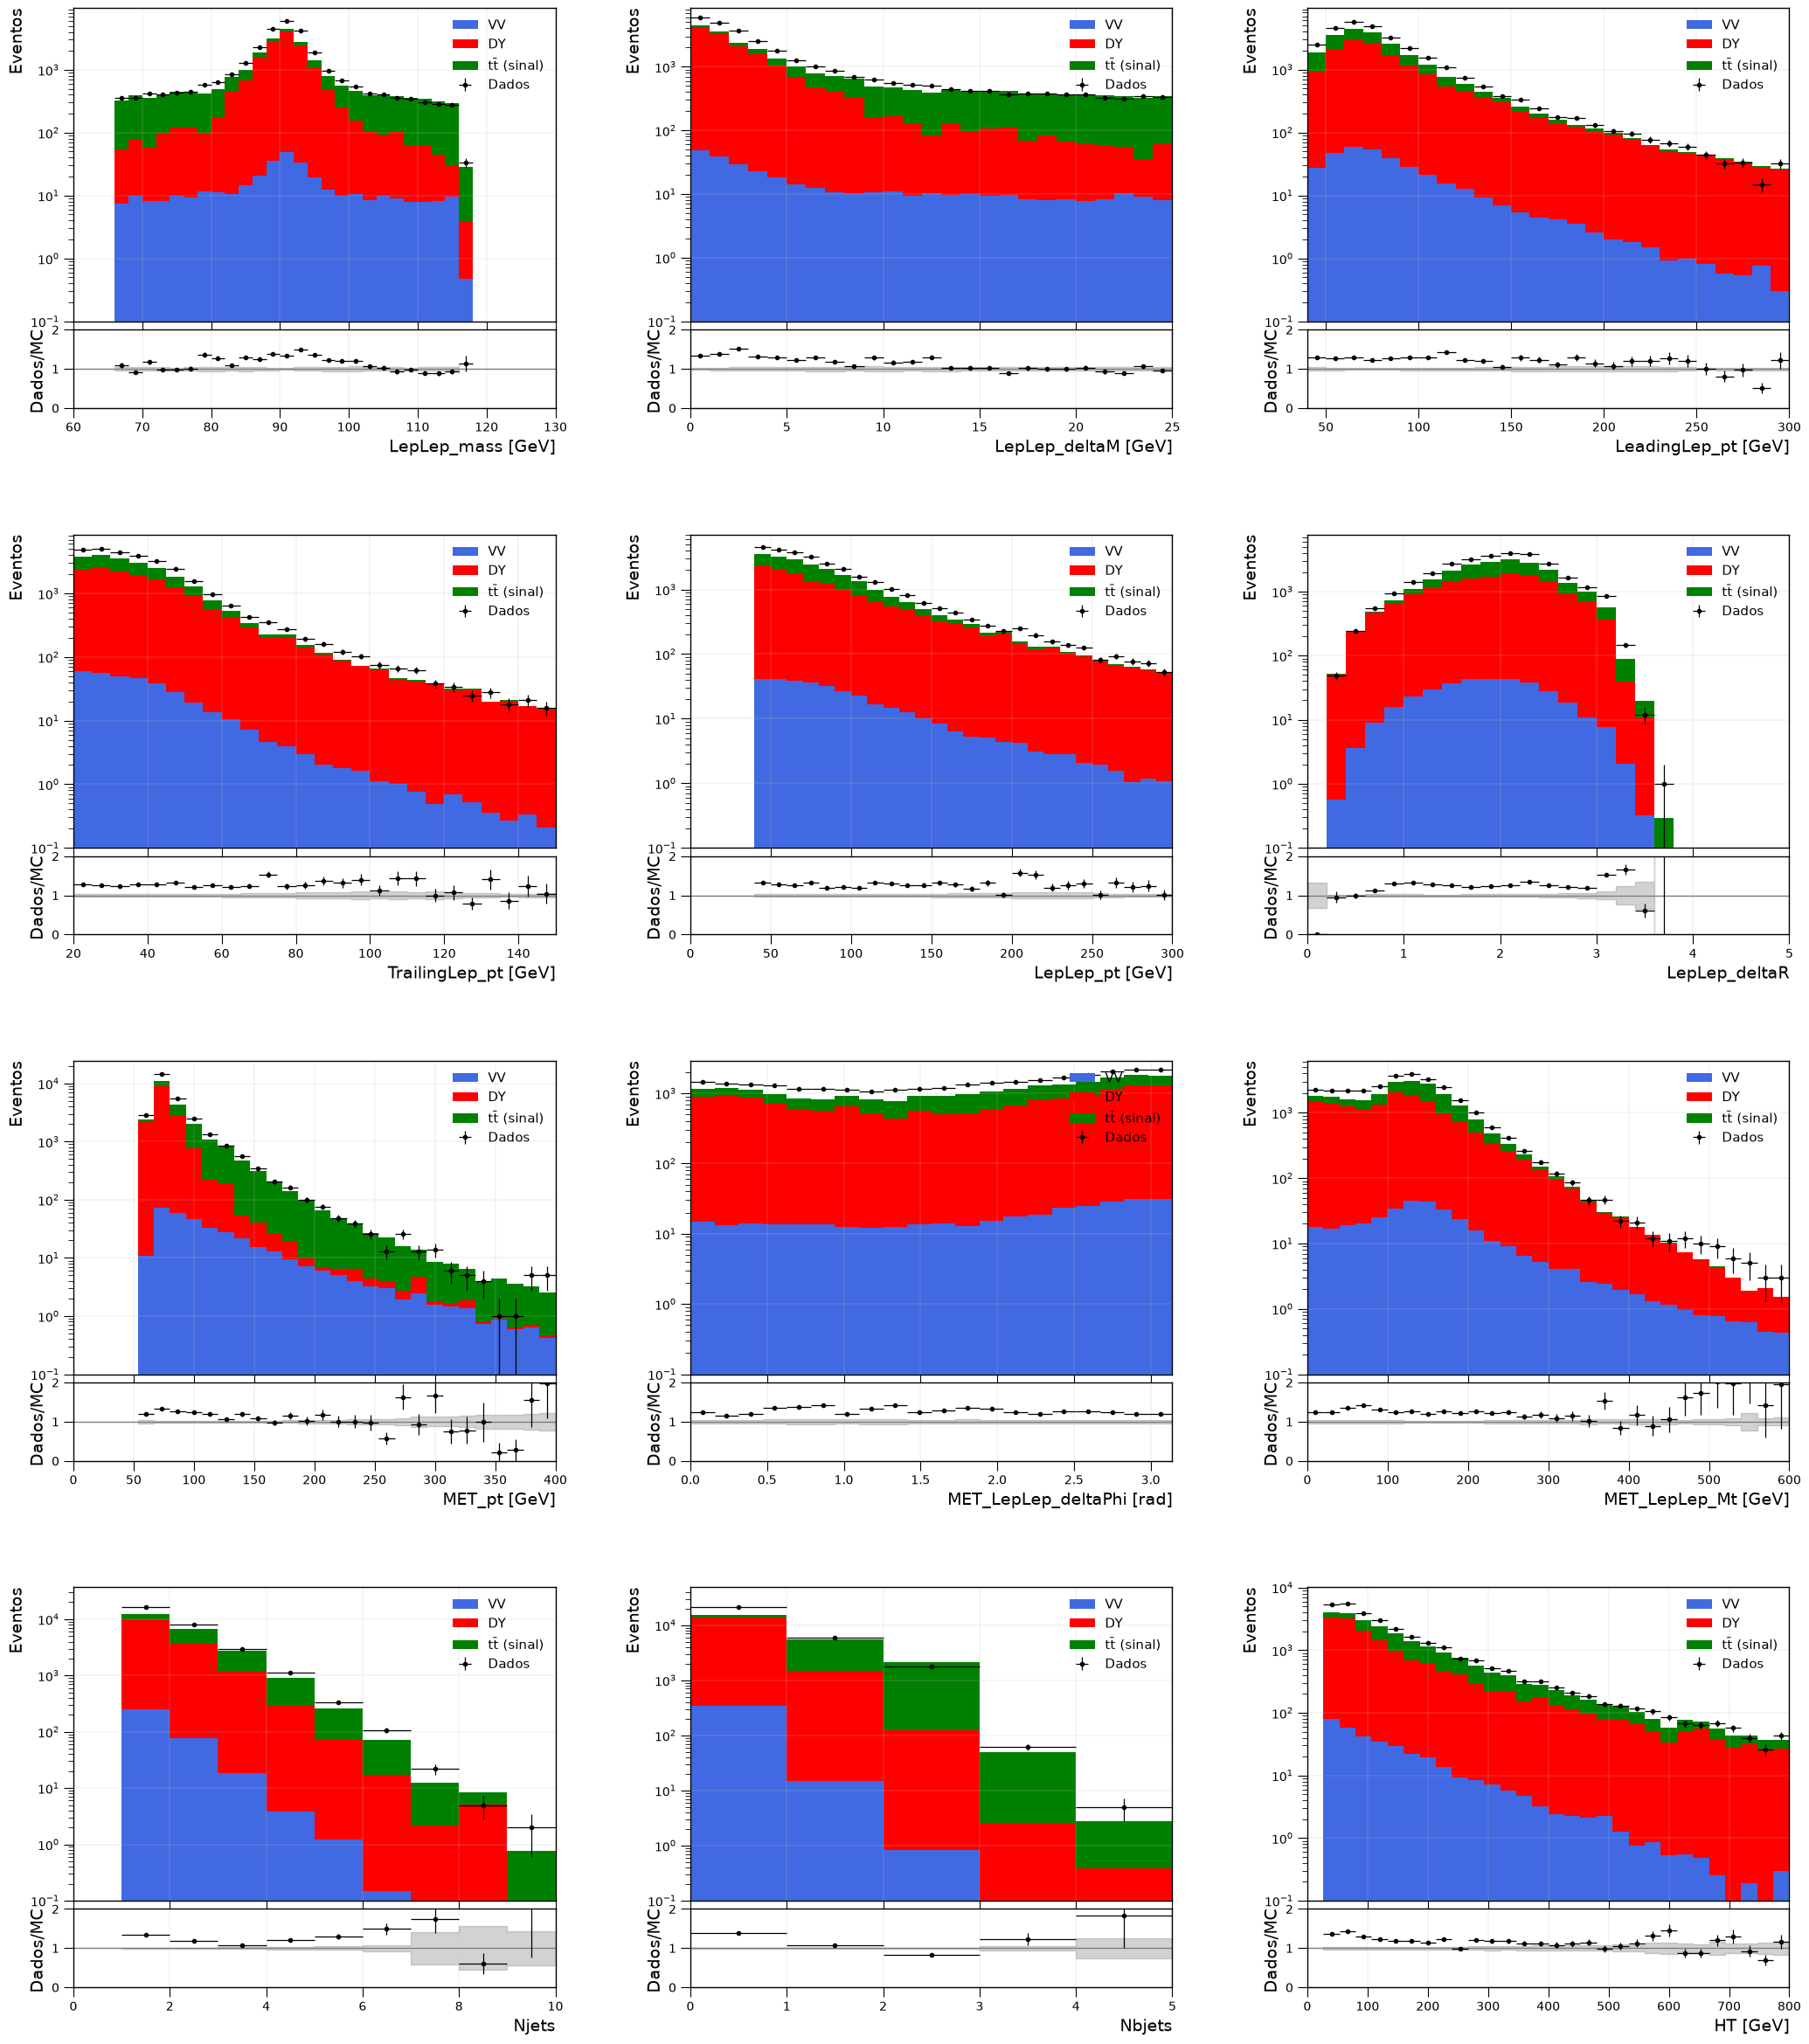

In [29]:
df = df_region

fig1 = plt.figure(figsize=(21,25))
grid = [12, 3]
gs1 = gs.GridSpec(grid[0], grid[1], height_ratios=[4, 1, 1.4]*4)   # painel principal, razão, espaço
#
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 0])
var = "LepLep_mass"
bins = np.linspace(60., 130, 36)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 1])
var = "LepLep_deltaM"
bins = np.linspace(0., DELTAM_MAX, 26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_deltaM [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 2])
var = "LeadingLep_pt"
bins = np.linspace(LEAD_MIN, 300, 27)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 0])
var = "TrailingLep_pt"
bins = np.linspace(TRAIL_MIN, 150, 27)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 1])
var = "LepLep_pt"
bins = np.linspace(0., 300, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 2])
var = "LepLep_deltaR"
bins = np.linspace(0., 5, 26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_deltaR", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 0])
var = "MET_pt"
bins = np.linspace(0., 400, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 1])
var = "MET_LepLep_deltaPhi"
bins = np.linspace(0., np.pi, 21)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_LepLep_deltaPhi [rad]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 2])
var = "MET_LepLep_Mt"
bins = np.linspace(0., 600, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_LepLep_Mt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 0])
var = "Njets"
bins = np.linspace(0., 10, 11)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="Njets", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 1])
var = "Nbjets"
bins = np.linspace(0., 5, 6)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="Nbjets", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 2])
var = "HT"
bins = np.linspace(0., 800, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.yscale("log")
plt.ylim(bottom=0.1)
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="HT [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
plt.subplots_adjust(left=0.05, bottom=0.03, right=0.985, top=0.99, wspace=0.28, hspace=0.05)
plt.savefig('dados_vs_mc_regiao.pdf')
plt.savefig('dados_vs_mc_regiao.png', dpi=300)

Data vs simulation with the signal selection (Figure B)<br>
=================================================================================================
Região + `Nbjets >= 1` e `Njets >= 2`. Escala linear.

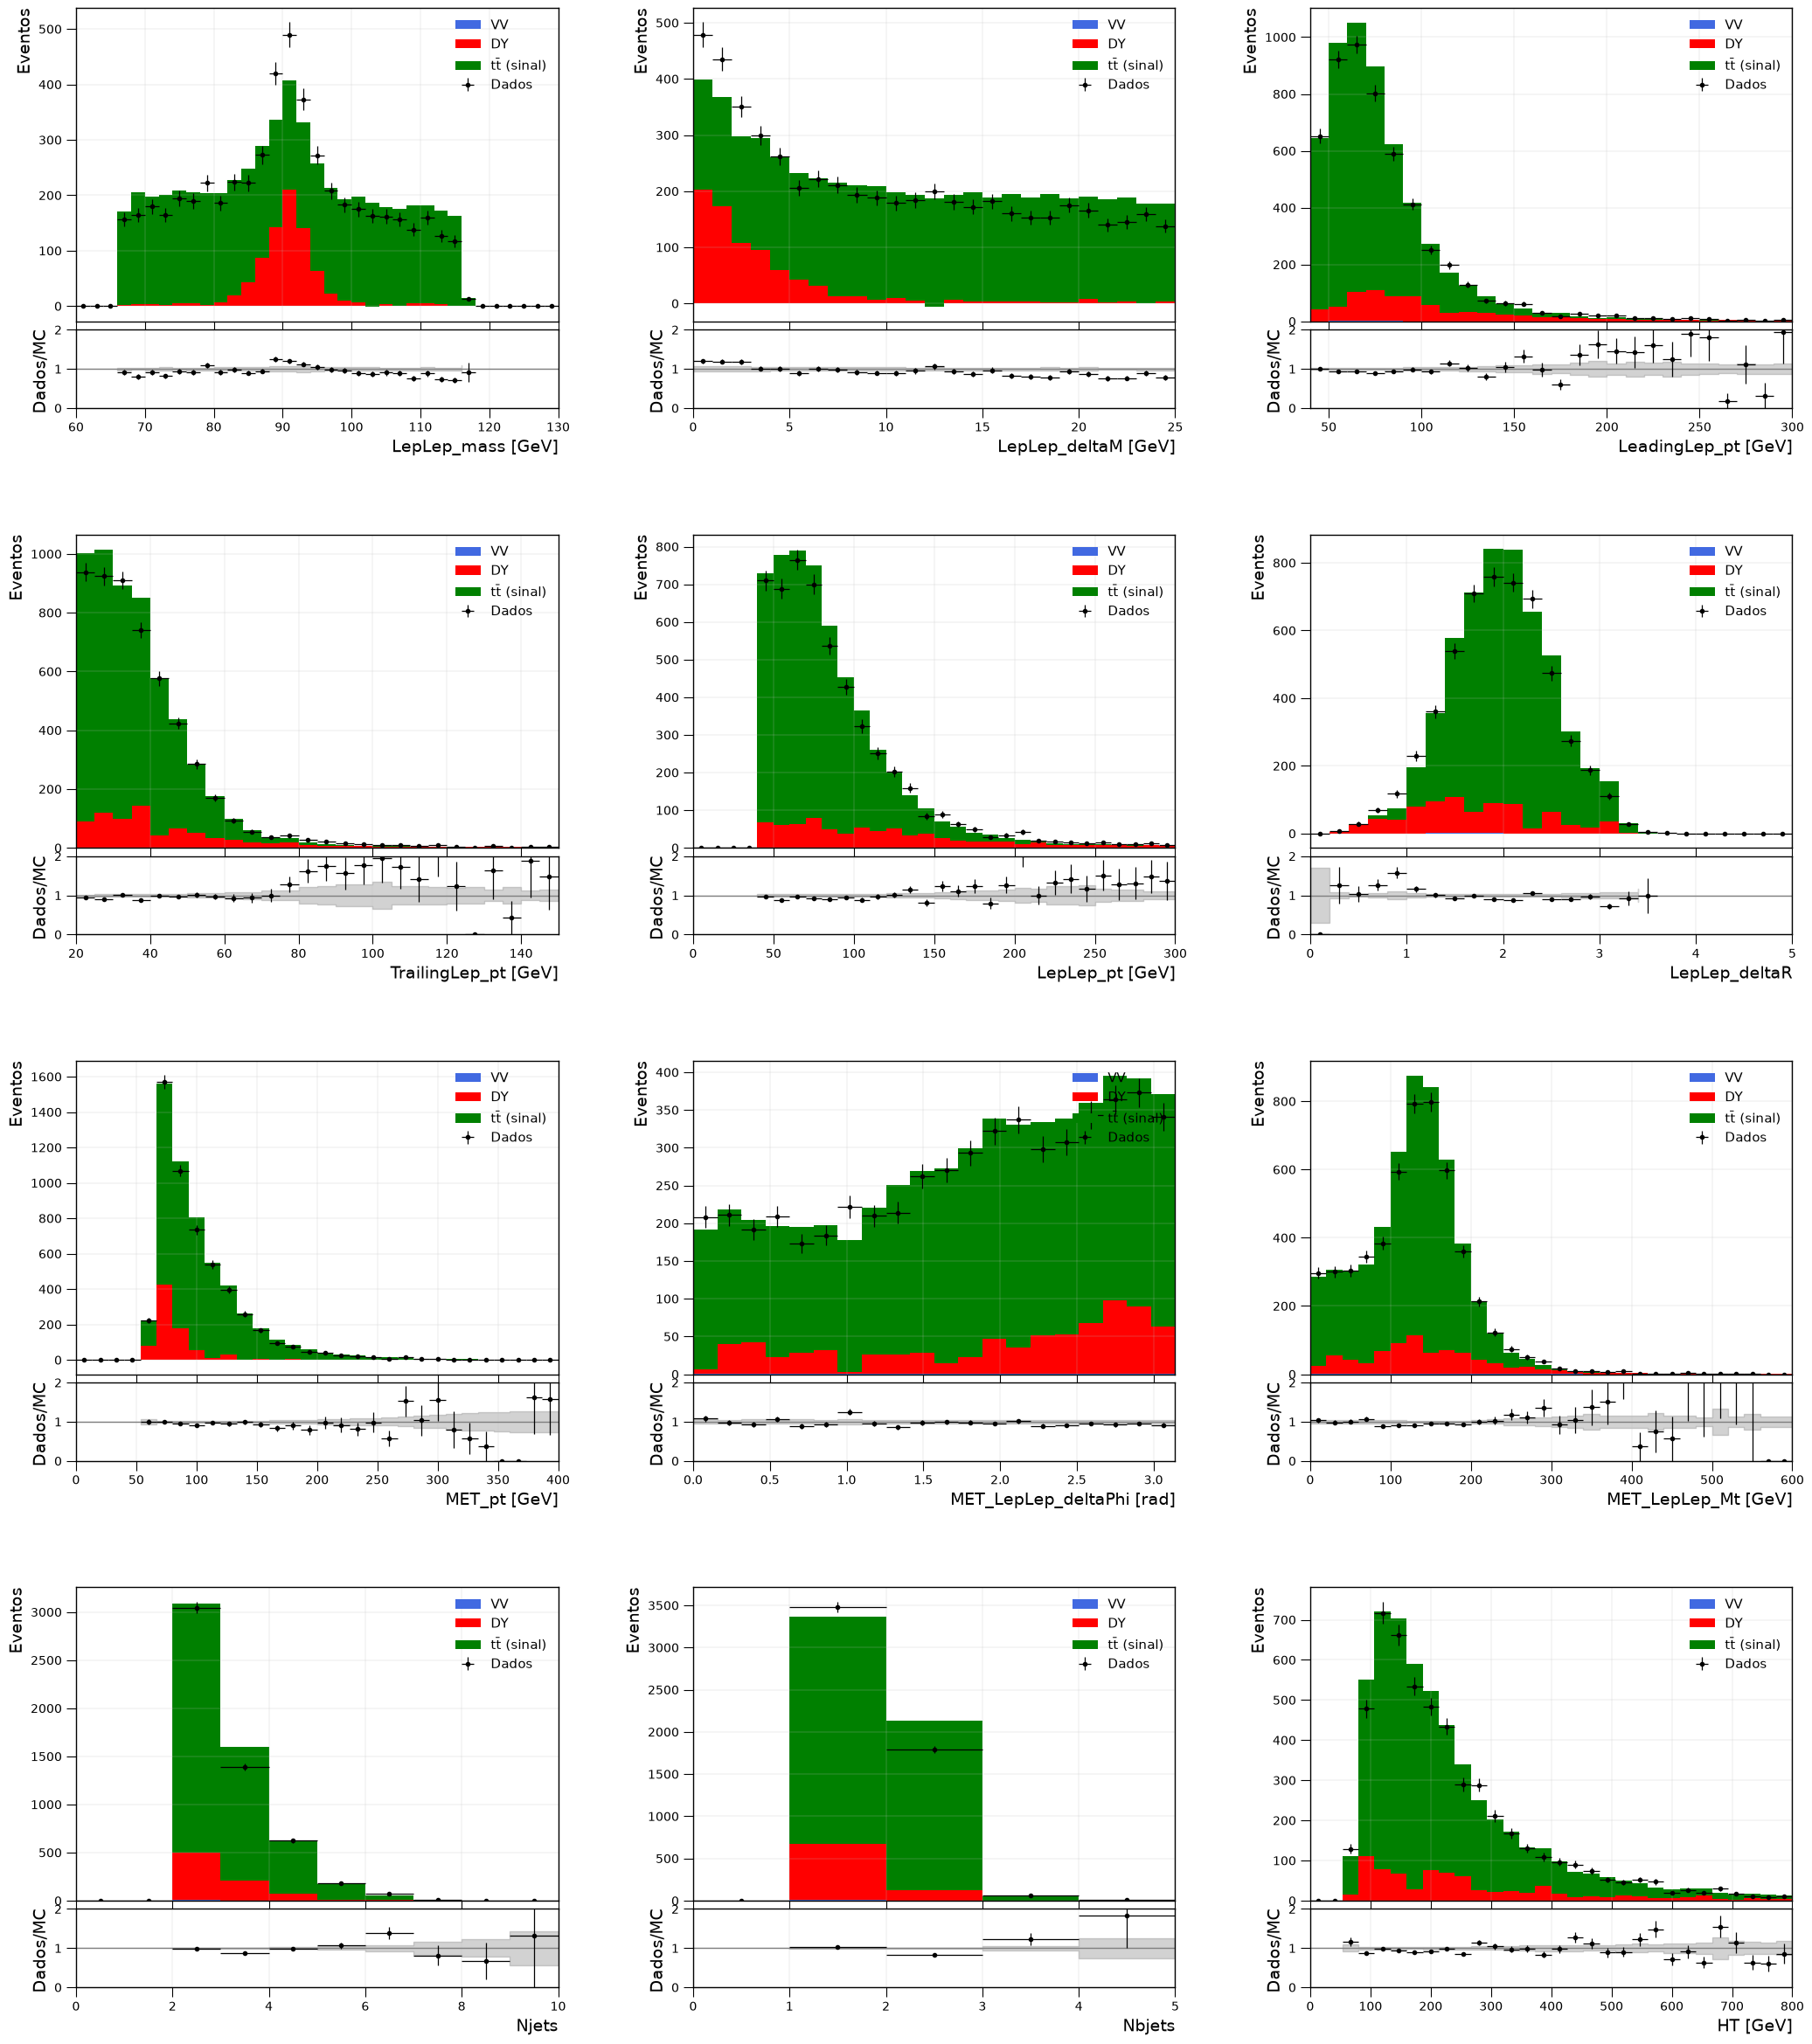

In [30]:
df = df_signal

fig1 = plt.figure(figsize=(21,25))
grid = [12, 3]
gs1 = gs.GridSpec(grid[0], grid[1], height_ratios=[4, 1, 1.4]*4)   # painel principal, razão, espaço
#
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 0])
var = "LepLep_mass"
bins = np.linspace(60., 130, 36)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 1])
var = "LepLep_deltaM"
bins = np.linspace(0., DELTAM_MAX, 26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_deltaM [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0, 2])
var = "LeadingLep_pt"
bins = np.linspace(LEAD_MIN, 300, 27)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[1, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LeadingLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 0])
var = "TrailingLep_pt"
bins = np.linspace(TRAIL_MIN, 150, 27)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="TrailingLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 1])
var = "LepLep_pt"
bins = np.linspace(0., 300, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[3, 2])
var = "LepLep_deltaR"
bins = np.linspace(0., 5, 26)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[4, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="LepLep_deltaR", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 0])
var = "MET_pt"
bins = np.linspace(0., 400, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_pt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 1])
var = "MET_LepLep_deltaPhi"
bins = np.linspace(0., np.pi, 21)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_LepLep_deltaPhi [rad]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[6, 2])
var = "MET_LepLep_Mt"
bins = np.linspace(0., 600, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[7, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="MET_LepLep_Mt [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 0])
var = "Njets"
bins = np.linspace(0., 10, 11)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 0])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="Njets", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 1])
var = "Nbjets"
bins = np.linspace(0., 5, 6)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 1])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="Nbjets", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[9, 2])
var = "HT"
bins = np.linspace(0., 800, 31)
dx = np.array([ (bins[i+1]-bins[i]) for i in range(bins.size-1)])
x_inf = bins[:-1]
x_mean = x_inf + 0.5*dx
SM_values = [df["VV"][var], df["DYJetsToLL"][var], df["TT"][var]]
SM_weights = [df["VV"]["evtWeight"], df["DYJetsToLL"]["evtWeight"], df["TT"]["evtWeight"]]
SM_labels = ["VV", "DY", "tt̄ (sinal)"]
SM_colors = ['royalblue', 'red', 'green']
SM_hist, b_dummy, p_dummy = plt.hist( SM_values, bins=bins, linewidth=1.5, weights=SM_weights, label=SM_labels, color=SM_colors, stacked=True )
VV_w2 = np.histogram(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"]**2)[0]
DY_w2 = np.histogram(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"]**2)[0]
TT_w2 = np.histogram(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"]**2)[0]
MC_err = np.sqrt(VV_w2 + DY_w2 + TT_w2)
Data_hist = np.histogram(df["Data"][var], bins=bins)[0]
ax1.errorbar(x_mean, Data_hist, xerr=0.5*dx, yerr=np.sqrt(Data_hist), fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0, label="Dados")
plt.xlim(bins[0], bins[-1])
plt.setp(ax1.get_xticklabels(), visible=False)
style(ax1)
labels( ax1, xlabel=None, ylabel="Eventos")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[10, 2])
MC_safe = np.where(SM_hist[-1] > 0, SM_hist[-1], np.nan)
ratio = Data_hist / MC_safe
ratio_err = np.sqrt(Data_hist) / MC_safe
band = MC_err / MC_safe
plt.axhline(1, color="gray", lw=1)
plt.fill_between(bins, np.append(1 - band, (1 - band)[-1]), np.append(1 + band, (1 + band)[-1]), step="post", color="gray", alpha=0.35)
ax1.errorbar(x_mean, ratio, xerr=0.5*dx, yerr=ratio_err, fmt='.', ecolor='black', color='black', elinewidth=0.9, capsize=0)
plt.xlim(bins[0], bins[-1])
plt.ylim(0., 2.0)
style(ax1, legend=False)
labels( ax1, xlabel="HT [GeV]", ylabel="Dados/MC")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
plt.subplots_adjust(left=0.05, bottom=0.03, right=0.985, top=0.99, wspace=0.28, hspace=0.05)
plt.savefig('dados_vs_mc_sinal.pdf')
plt.savefig('dados_vs_mc_sinal.png', dpi=300)

In [31]:
print("Eventos esperados após a seleção final (16.4 fb^-1):")
print("tt̄  ", df_signal["TT"]["evtWeight"].sum())
print("DY  ", df_signal["DYJetsToLL"]["evtWeight"].sum())
print("VV  ", df_signal["VV"]["evtWeight"].sum())
print("Dados", len(df_signal["Data"]))

Eventos esperados após a seleção final (16.4 fb^-1):
tt̄   4758.893
DY   786.4063
VV   7.8464956
Dados 5333


In [32]:
d = df_channel["TT"]
print(d["Njets"].value_counts().sort_index())
print("HT minimo:", d["HT"].min())
print("min(HT/Njets):", (d["HT"]/d["Njets"]).min())

Njets
1     45458
2     69955
3     36334
4     14240
5      4444
6      1222
7       307
8        83
9        20
10        8
Name: count, dtype: int64
HT minimo: 30.015625
min(HT/Njets): 30.015625


In [37]:
df_channel["TT"]["BJetLep_mass"].describe()

count    172071.000000
mean         93.495872
std          48.606403
min          12.270184
25%          64.463055
50%          89.337357
75%         114.125763
max        1682.701782
Name: BJetLep_mass, dtype: float64

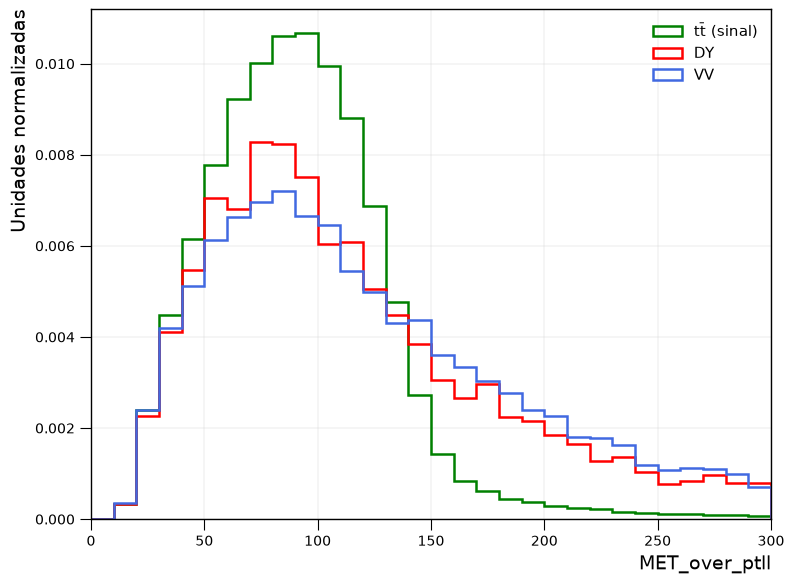

In [36]:
df = df_channel # ou df_region, df_signal...
fig1 = plt.figure(figsize=(8,6))
gs1 = gs.GridSpec(1, 1)
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
ax1 = plt.subplot(gs1[0])
var = "BJetLep_mass"
bins = np.linspace(0., 300., 31)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], density=True, linewidth=1.8,
 color='green', histtype='step', label="tt̄ (sinal)")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], density=True,
 linewidth=1.8, color='red', histtype='step', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], density=True, linewidth=1.8,
 color='royalblue', histtype='step', label="VV")
style(ax1)
labels( ax1, xlabel="MET_over_ptll", ylabel="Unidades normalizadas")
#~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
plt.subplots_adjust(left=0.12, bottom=0.12, right=0.97, top=0.97)
plt.savefig('nova_variavel_forma.png', dpi=200)


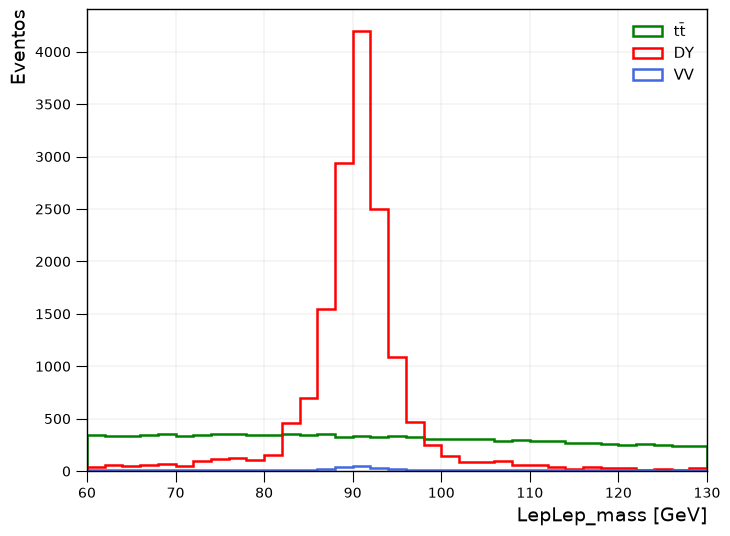

In [38]:
plt.figure(figsize=(8,6))
ax1 = plt.subplot(1,1,1)
var = "LepLep_mass"
bins = np.linspace(60., 130, 36)
plt.hist(df["TT"][var], bins=bins, weights=df["TT"]["evtWeight"], histtype='step', linewidth=1.8, color='green', label="tt̄")
plt.hist(df["DYJetsToLL"][var], bins=bins, weights=df["DYJetsToLL"]["evtWeight"], histtype='step', linewidth=1.8, color='red', label="DY")
plt.hist(df["VV"][var], bins=bins, weights=df["VV"]["evtWeight"], histtype='step', linewidth=1.8, color='royalblue', label="VV")
style(ax1)
labels( ax1, xlabel="LepLep_mass [GeV]", ylabel="Eventos")